## HistGradientBoosting Classifier: Job Satisfaction (NSCG 2023 + O*NET)

## Overview
This notebook trains a `HistGradientBoostingClassifier` to predict whether a college graduate is **very satisfied** with their job (`JOBSATIS == 1`) using the cleaned NSCG 2023 + O*NET dataset (`data/processed/nscg2023_onet_clean.csv`, 79,800 respondents, 43.9% very satisfied). It follows the workflow of the GSS `HistGradientBoosting.ipynb` notebook and reuses the repo's NSCG feature definitions, loader, metrics and threshold rule so results line up with the NSCG logistic regression and decision tree baselines.

## Data Preparation & Preprocessing
- **Target:** `very_satisfied` (1 = very satisfied). Note the direction differs from the GSS notebook's mapping.
- **Feature sets (nested):** **A0** = respondent and job context (28 raw columns); **A1** = A0 + O*NET Work Values and job zone (35); **A2** = A1 + the nine `FAC*` person-value ratings + person-job fit terms (z-product and gap for five FAC / Work Value pairs) (44).
- **Missing values:** passed to HGB as NaN, with no imputation. Software developers (NCSES 110590, ~5% of rows) have no Work Values and stay blank.
- **Categoricals:** nine nominal columns (including 2-digit `occ_group`) are ordinal-coded inside the pipeline and flagged for HGB's native categorical splits (no one-hot). `FitFeatures` is also inside the pipeline, so its z-scores use training rows only.
- **Split:** stratified 80/20 (`random_state=42`): 63,840 train / 15,960 test, shared by all three feature sets.

## Model & Hyperparameter Tuning
`class_weight="balanced"` and early stopping (`max_iter` cap 500, 15 rounds without improvement), as in the LR / DT baselines. 5-fold `GridSearchCV` optimizing **ROC-AUC** (not accuracy, since this is a modest class imbalance and the NSCG baselines tune on AUC), 144 combinations per feature set:
- `learning_rate`: `[0.03, 0.06, 0.1]`
- `max_depth`: `[2, 3, 5, 8]`
- `min_samples_leaf`: `[50, 100, 250, 500]` (larger than the GSS notebook because there are ~64k training rows)
- `l2_regularization`: `[0.0, 1.0, 10.0]`

| Set | Best params | CV ROC-AUC |
|---|---|---|
| A0 | lr 0.06, depth 3, leaf 500, l2 10 | 0.668 |
| A1 | lr 0.06, depth 3, leaf 500, l2 10 | 0.668 |
| A2 | lr 0.10, depth 3, leaf 500, l2 0 | 0.709 |

A0 and A1 chose the grid edge for `min_samples_leaf` (500) and `l2_regularization` (10), so they would likely prefer even stronger regularization. The gain from extending the grid is expected to be small.

## Results & Performance (test set, unweighted, bootstrap 95% CI)
The decision threshold maximises F1 on out-of-fold predictions of the training set only.

| Metric | A0 | A1 | A2 |
|---|---|---|---|
| ROC-AUC | 0.659 [0.651, 0.667] | 0.662 [0.654, 0.671] | **0.705** [0.698, 0.714] |
| PR-AUC | 0.598 | 0.602 | **0.645** |
| Balanced accuracy | 0.576 | 0.576 | **0.622** |
| F1 (very satisfied) | 0.627 | 0.629 | **0.646** |
| Brier score | 0.230 | 0.229 | **0.218** |

- **O*NET Work Values alone add very little:** A1 - A0 = +0.003 ROC-AUC (statistically detectable but practically small).
- **The person-side value ratings and fit terms add much more:** A2 - A1 = +0.043 ROC-AUC (95% CI 0.037 to 0.049). This is consistent with the advisor's reason for choosing NSCG for the app. A2 contains both the raw `FAC*` ratings and the fit terms, so this notebook cannot separate "person values matter" from "fit between person and job matters".
- **Versus baselines (pooled nested-CV OOF; not an exact like-for-like comparison):** A2 ROC-AUC is 0.705 for HGB, 0.693 for logistic regression and 0.662 for the decision tree. The HGB gain over LR is about 0.01 AUC.
- **Top A2 permutation importances:** `log_salary` (0.041), then `FACSEC`, `FACRESP`, `OCEDRLP`, `FACCHAL`.
- **Weighted by `WTSURVY`:** A2 ROC-AUC is 0.705, similar to unweighted.
- **A2 classification report:** at the tuned threshold (0.386), recall for "very satisfied" is 0.84 and precision 0.52, with overall accuracy 0.595. At 0.50, accuracy is 0.645 with balanced precision and recall. The F1-tuned threshold favours recall on the positive class.
- **Software developers (no Work Values):** test AUC is lower for this group (A2: 0.661 vs 0.708 for everyone else). A0 shows the same gap (0.607 vs 0.662), so it is not caused by the missing O*NET values. Retraining without developers changes AUC on the other occupations by about 0.0001 to 0.0003.

Saved outputs: `results/nscg/nscg_hgb_point_metrics.csv`, `nscg_hgb_point_metrics_weighted.csv`, `nscg_hgb_chosen_params.csv`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

# repo helpers: the same feature definitions, loader, metrics and threshold rule as the NSCG LR / DT baselines
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "models").is_dir())
sys.path.insert(0, str(ROOT / "src" / "models"))
from nscg_features import FEATURE_SETS, FIT_COLS, FIT_PAIRS, FitFeatures
from nscg_lr_baseline import BOOT_SEED, load_data, metrics_one
from rf_baseline import SEED, best_f1_threshold, make_boot_indices

import matplotlib.pyplot as plt

# the baseline modules switch matplotlib to a non-interactive backend on import; switch back for inline plots
%matplotlib inline
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
# Load the cleaned NSCG + O*NET data (rebuild with notebooks/nscg/nscg_cleaning.ipynb; the CSV is gitignored).
# load_data() coerces dtypes, clips implausibly low salaries and asserts no JOBSATIS / SAT* leakage columns.
# Target: very_satisfied (JOBSATIS == 1) = 1, ~44% of respondents.
df, y, w = load_data(ROOT / "data" / "processed" / "nscg2023_onet_clean.csv")

# Stratified 80/20 split, shared by every feature set so A0 / A1 / A2 are scored on the same people
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.2, random_state=42, stratify=y)
y_train, y_test, w_test = y[train_idx], y[test_idx], w[test_idx]
print(f"train = {len(train_idx)}, test = {len(test_idx)}, "
      f"very satisfied: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

n = 79800, very satisfied = 35058 (43.9% unweighted, 44.1% weighted)
train = 63840, test = 15960, very satisfied: train 43.9%, test 43.9%


In [3]:
def feature_frame(spec):
    # raw columns for a feature set; fit terms are derived inside the pipeline so z-scores use training rows only
    cols = spec["num"] + spec["cat"] + (FIT_COLS if spec["fit"] else [])
    return df[list(dict.fromkeys(cols))].copy()


def build_pipeline(spec):
    # HGB handles NaN natively, so there is no imputer, scaler or one-hot step.
    # Categoricals are ordinal-coded (unseen / missing -> NaN) and flagged for HGB's native categorical splits.
    parts = [
        ("num", "passthrough", spec["num"]),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               encoded_missing_value=np.nan), spec["cat"]),
    ]
    is_cat = [False] * len(spec["num"]) + [True] * len(spec["cat"])
    if spec["fit"]:
        parts.append(("fit", FitFeatures(pairs=FIT_PAIRS), FIT_COLS))
        is_cat += [False] * (2 * len(FIT_PAIRS))  # a product and a gap per Work Value pair
    hgb = HistGradientBoostingClassifier(
        categorical_features=is_cat,
        class_weight="balanced",  # same as the LR / DT baselines
        early_stopping=True, n_iter_no_change=15, validation_fraction=0.1, max_iter=500,
        random_state=SEED,
    )
    return Pipeline([("pre", ColumnTransformer(parts)), ("clf", hgb)])


X_sets = {name: feature_frame(spec) for name, spec in FEATURE_SETS.items()}
for name, X in X_sets.items():
    print(f"{name}: {X.shape[1]} raw columns")

A0: 28 raw columns
A1: 35 raw columns
A2: 44 raw columns


### Hyperparameter tuning
`max_iter` is capped at 500 and set by early stopping rather than searched. `min_samples_leaf` is larger than in the GSS notebook because there are ~64k training rows instead of ~2.2k.

In [4]:
param_grid = {
    "clf__learning_rate": [0.03, 0.06, 0.1],
    "clf__max_depth": [2, 3, 5, 8],
    "clf__min_samples_leaf": [50, 100, 250, 500],
    "clf__l2_regularization": [0.0, 1.0, 10.0],
}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

searches = {}
for name, spec in FEATURE_SETS.items():
    t0 = time.time()
    gs = GridSearchCV(build_pipeline(spec), param_grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_sets[name].iloc[train_idx], y_train)
    searches[name] = gs
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.4f} ({time.time() - t0:.0f}s, "
          f"{gs.best_estimator_['clf'].n_iter_} boosting iterations)")
    print("    ", {k.replace("clf__", ""): v for k, v in gs.best_params_.items()})

A0: best CV ROC-AUC = 0.6676 (287s, 302 boosting iterations)
     {'l2_regularization': 10.0, 'learning_rate': 0.06, 'max_depth': 3, 'min_samples_leaf': 500}


A1: best CV ROC-AUC = 0.6678 (351s, 379 boosting iterations)
     {'l2_regularization': 10.0, 'learning_rate': 0.06, 'max_depth': 3, 'min_samples_leaf': 500}


A2: best CV ROC-AUC = 0.7090 (558s, 244 boosting iterations)
     {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 500}


### Test-set evaluation
The decision threshold maximises F1 on out-of-fold predictions of the **training** set only (the NSCG LR / DT rule), so the test set is touched once. ROC-AUC, PR-AUC and Brier score do not depend on the threshold.

In [5]:
results = {}
for name in FEATURE_SETS:
    best = searches[name].best_estimator_
    X_train, X_test = X_sets[name].iloc[train_idx], X_sets[name].iloc[test_idx]
    p_inner = cross_val_predict(clone(best), X_train, y_train, cv=inner_cv,
                                method="predict_proba", n_jobs=-1)[:, 1]
    thr = best_f1_threshold(y_train, p_inner)
    p_test = best.predict_proba(X_test)[:, 1]
    results[name] = dict(p=p_test, thr=thr, hard=(p_test >= thr).astype(int))

# 95% CIs: stratified bootstrap of the test people (1,000 resamples), shared across sets so comparisons are paired
boot_idx = make_boot_indices(y_test, 1000, BOOT_SEED)
rows, rows_w, boot = [], [], {}
for name, r in results.items():
    point = metrics_one(y_test, r["p"], r["hard"])
    point_w = metrics_one(y_test, r["p"], r["hard"], w_test)
    draws = pd.DataFrame(Parallel(n_jobs=-1)(
        delayed(metrics_one)(y_test[i], r["p"][i], r["hard"][i]) for i in boot_idx))
    boot[name] = draws
    for m, v in point.items():
        lo, hi = np.percentile(draws[m], [2.5, 97.5])
        rows.append(dict(set=name, metric=m, value=v, ci_low=lo, ci_high=hi))
    rows_w += [dict(set=name, metric=m, value=v) for m, v in point_w.items()]

hgb_tab, hgb_tab_w = pd.DataFrame(rows), pd.DataFrame(rows_w)
fmt = lambda t: t.assign(s=t.apply(lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)) \
                 .pivot(index="metric", columns="set", values="s").loc[list(point)]
print("Test-set metrics, unweighted (bootstrap 95% CI)")
print(fmt(hgb_tab).to_string())
print("\nThresholds:", {n: round(r["thr"], 3) for n, r in results.items()})
print("\nTest-set metrics, weighted by WTSURVY (point estimates)")
print(hgb_tab_w.pivot(index="metric", columns="set", values="value").loc[list(point)].round(3).to_string())
print(f"\nprevalence (PR-AUC floor) = {y_test.mean():.3f}")

Test-set metrics, unweighted (bootstrap 95% CI)
set                                           A0                    A1                    A2
metric                                                                                      
ROC-AUC                     0.659 [0.651, 0.667]  0.662 [0.654, 0.671]  0.705 [0.698, 0.714]
PR-AUC                      0.598 [0.588, 0.608]  0.602 [0.592, 0.612]  0.645 [0.635, 0.655]
Balanced accuracy           0.576 [0.570, 0.582]  0.576 [0.570, 0.582]  0.622 [0.615, 0.628]
Brier score                 0.230 [0.228, 0.232]  0.229 [0.227, 0.232]  0.218 [0.215, 0.220]
Precision (very satisfied)  0.486 [0.482, 0.490]  0.486 [0.482, 0.490]  0.524 [0.519, 0.529]
Recall (very satisfied)     0.883 [0.876, 0.891]  0.890 [0.883, 0.898]  0.841 [0.832, 0.849]
F1 (very satisfied)         0.627 [0.622, 0.632]  0.629 [0.624, 0.633]  0.646 [0.640, 0.651]
Macro-F1                    0.511 [0.504, 0.518]  0.508 [0.501, 0.516]  0.586 [0.579, 0.594]

Thresholds: {'A0': 0.

In [6]:
# Paired bootstrap on ROC-AUC: does adding O*NET (A1 - A0) or the person-value / fit features (A2 - A1) help?
diffs = []
for hi, lo in [("A1", "A0"), ("A2", "A1")]:
    d = boot[hi]["ROC-AUC"].to_numpy() - boot[lo]["ROC-AUC"].to_numpy()
    ci = np.percentile(d, [2.5, 97.5])
    point_diff = roc_auc_score(y_test, results[hi]["p"]) - roc_auc_score(y_test, results[lo]["p"])
    diffs.append(dict(comparison=f"{hi} - {lo}", auc_diff=point_diff, ci_low=ci[0], ci_high=ci[1],
                      bootstrap_p=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
print(pd.DataFrame(diffs).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

comparison  auc_diff  ci_low  ci_high  bootstrap_p
   A1 - A0    0.0029  0.0018   0.0041       0.0000
   A2 - A1    0.0432  0.0373   0.0489       0.0000


### Comparison with the logistic regression and decision tree baselines
Caveat: the LR / DT numbers are pooled out-of-fold results from 5x5 nested cross-validation over all 79,800 rows, while the HGB numbers come from a single 80/20 split (15,960 test rows). They are close in spirit but not an exact like-for-like comparison.

In [7]:
metrics_to_show = ["ROC-AUC", "PR-AUC", "Balanced accuracy", "F1 (very satisfied)"]
frames = []
for label, prefix in [("Logistic regression", "nscg_lr"), ("Decision tree", "nscg_dt")]:
    t = pd.read_csv(ROOT / "results" / "nscg" / f"{prefix}_point_metrics.csv")
    frames.append(t.assign(model=label))
frames.append(hgb_tab.assign(model="HistGradientBoosting"))
cmp = pd.concat(frames)
cmp = cmp[cmp.metric.isin(metrics_to_show)]
print(cmp.pivot_table(index="metric", columns=["model", "set"], values="value").loc[metrics_to_show].round(3).to_string())

model               Decision tree               HistGradientBoosting               Logistic regression              
set                            A0     A1     A2                   A0     A1     A2                  A0     A1     A2
metric                                                                                                              
ROC-AUC                     0.639  0.638  0.662                0.659  0.662  0.705               0.652  0.652  0.693
PR-AUC                      0.572  0.570  0.595                0.598  0.602  0.645               0.590  0.590  0.634
Balanced accuracy           0.549  0.548  0.575                0.576  0.576  0.622               0.566  0.567  0.611
F1 (very satisfied)         0.620  0.620  0.629                0.627  0.629  0.646               0.624  0.624  0.640


In [8]:
# Classification reports for the full-feature model (A2): default 0.5 cut-off and the tuned F1 cut-off
r = results["A2"]
for title, hard in [("threshold = 0.50", (r["p"] >= 0.5).astype(int)), (f"tuned threshold = {r['thr']:.3f}", r["hard"])]:
    print(f"--- A2, {title} ---")
    print(classification_report(y_test, hard, target_names=["not very satisfied", "very satisfied"], digits=3))

--- A2, threshold = 0.50 ---
                    precision    recall  f1-score   support

not very satisfied      0.702     0.639     0.669      8948
    very satisfied      0.587     0.654     0.618      7012

          accuracy                          0.645     15960
         macro avg      0.644     0.646     0.644     15960
      weighted avg      0.651     0.645     0.647     15960

--- A2, tuned threshold = 0.386 ---
                    precision    recall  f1-score   support

not very satisfied      0.763     0.402     0.527      8948
    very satisfied      0.524     0.841     0.646      7012

          accuracy                          0.595     15960
         macro avg      0.644     0.622     0.586     15960
      weighted avg      0.658     0.595     0.579     15960



log_salary    0.0412
FACSEC        0.0155
FACRESP       0.0132
OCEDRLP       0.0109
FACCHAL       0.0087
TELEC         0.0081
HRSWK         0.0080
EMSIZE        0.0075
RACETHM       0.0069
FACSOC        0.0069
FACADV        0.0068
CTZN          0.0060
NEDTP         0.0057
FACIND        0.0048
JOBPROFT      0.0046


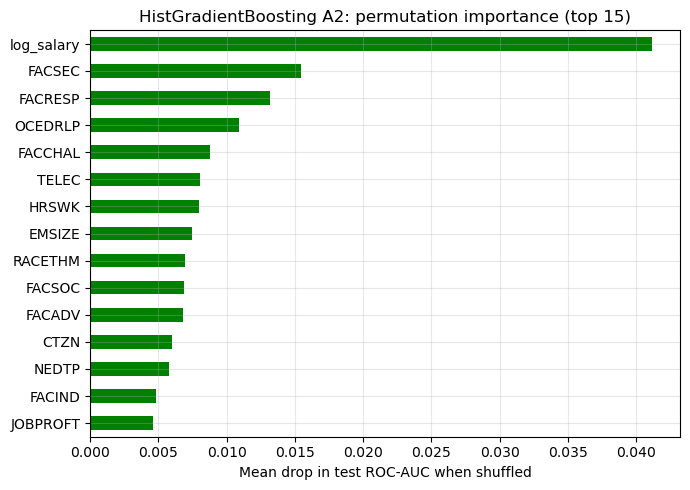

In [9]:
# Permutation importance for A2 on the held-out test set (drop in ROC-AUC when a raw column is shuffled)
best_a2 = searches["A2"].best_estimator_
pi = permutation_importance(best_a2, X_sets["A2"].iloc[test_idx], y_test, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_sets["A2"].columns).sort_values(ascending=False)
print(imp.head(15).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 5))
imp.head(15)[::-1].plot.barh(ax=ax, color="green")
ax.set_xlabel("Mean drop in test ROC-AUC when shuffled")
ax.set_title("HistGradientBoosting A2: permutation importance (top 15)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Software developers (no O*NET Work Values)
NCSES occupation 110590 has no Work Values in O*NET 30.2 (about 5% of respondents), and those values are deliberately left blank rather than imputed. HGB routes the missing values natively, so no flag column is needed. Two checks: (1) how does each model score on this group compared with everyone else, and (2) does training with or without them change performance on the other occupations?

In [10]:
is_dev = (df["N3OCPR"] == "110590").to_numpy()
dev_train, dev_test = is_dev[train_idx], is_dev[test_idx]
print(f"software developers: {dev_train.sum()} train rows, {dev_test.sum()} test rows")

rows = []
for name in FEATURE_SETS:
    p = results[name]["p"]
    row = dict(set=name,
               AUC_all=roc_auc_score(y_test, p),
               AUC_devs=roc_auc_score(y_test[dev_test], p[dev_test]),
               AUC_non_devs=roc_auc_score(y_test[~dev_test], p[~dev_test]))
    if name != "A0":  # A0 has no O*NET inputs, so training with or without developers is a different question
        X = X_sets[name]
        refit = clone(searches[name].best_estimator_).fit(X.iloc[train_idx][~dev_train], y_train[~dev_train])
        row["AUC_non_devs_refit_without_devs"] = roc_auc_score(
            y_test[~dev_test], refit.predict_proba(X.iloc[test_idx][~dev_test])[:, 1])
    rows.append(row)
print(pd.DataFrame(rows).round(4).to_string(index=False))

software developers: 3276 train rows, 793 test rows


set  AUC_all  AUC_devs  AUC_non_devs  AUC_non_devs_refit_without_devs
 A0   0.6593    0.6067        0.6617                              NaN
 A1   0.6622    0.6098        0.6646                           0.6625
 A2   0.7054    0.6607        0.7076                           0.7057


In [11]:
# Save the HGB table in the same layout as results/nscg/nscg_{lr,dt}_point_metrics.csv
out = ROOT / "results" / "nscg"
out.mkdir(parents=True, exist_ok=True)
hgb_tab.to_csv(out / "nscg_hgb_point_metrics.csv", index=False)
hgb_tab_w.to_csv(out / "nscg_hgb_point_metrics_weighted.csv", index=False)
pd.DataFrame([{"set": n, **{k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
               "cv_roc_auc": gs.best_score_, "f1_threshold": results[n]["thr"]}
              for n, gs in searches.items()]).to_csv(out / "nscg_hgb_chosen_params.csv", index=False)
print("saved to", out)

saved to /Users/aaronashby/Coding/Fall AI Studio/Swytch-2C-predicting-job-satisfaction-from-person-job-fit/results/nscg
